Write a program to denoise the input image using adaptive median filter.
Input the initial window size and maximum size of window (Smax) from
the user. Compare the performance of median filter and adaptive median
filter, using the PSNR values.  

Enter initial window size (odd number): 17
Enter maximum window size (Smax): 233

PSNR Comparison
-------------------------
Median Filter PSNR: 22.72 dB
Adaptive Median Filter PSNR: 25.32 dB
Adaptive Median Filter gives better performance.


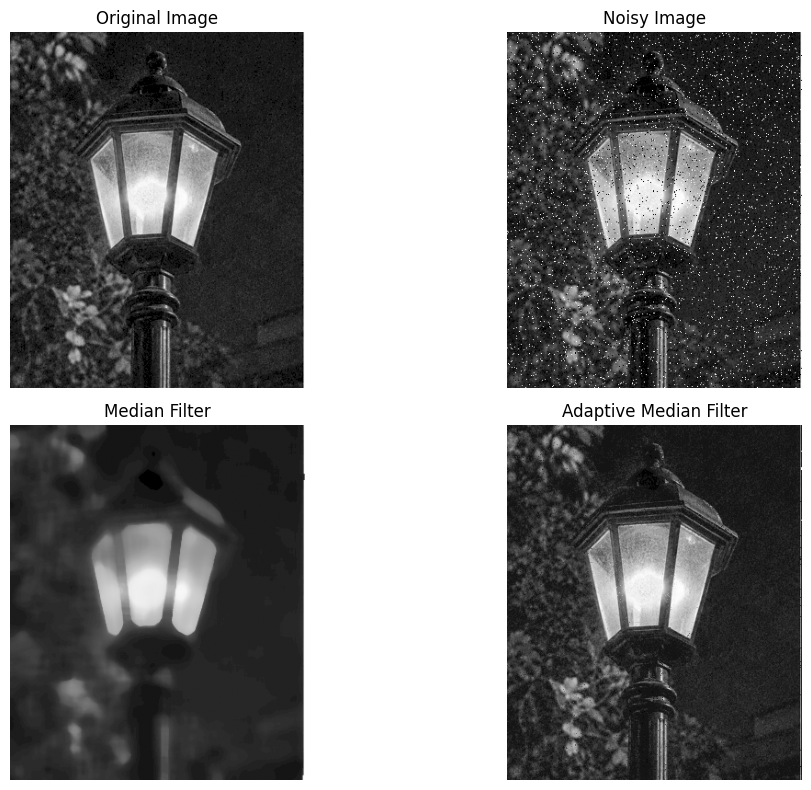

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read the input image
img = cv2.imread('/content/denoising.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()

# Step 2: Take window sizes from user
Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size (Smax): "))

if Smin < 3 or Smin % 2 == 0 or Smax < Smin or Smax % 2 == 0:
    print("Enter valid odd window sizes. Smin >= 3 and Smax >= Smin.")
    exit()

# Step 3: Add salt and pepper noise
noisy = img.copy()
prob = 0.05

random_values = np.random.random(img.shape)

noisy[random_values < prob / 2] = 0
noisy[random_values > 1 - prob / 2] = 255

# Step 4: Apply normal median filter
median_filtered = cv2.medianBlur(noisy, Smin)

# Step 5: Define adaptive median filter
def adaptive_median_filter(image, Smin, Smax):

    height, width = image.shape
    output = image.copy()
    pad = Smax // 2

    padded = cv2.copyMakeBorder(
        image, pad, pad, pad, pad,
        cv2.BORDER_REFLECT
    )

    for i in range(height):
        for j in range(width):

            window_size = Smin

            while window_size <= Smax:

                half = window_size // 2

                window = padded[
                    i + pad - half : i + pad + half + 1,
                    j + pad - half : j + pad + half + 1
                ]

                Zmin = np.min(window)
                Zmax = np.max(window)
                Zmed = np.median(window)
                Zxy = padded[i + pad, j + pad]

                # Stage A
                if Zmin < Zmed < Zmax:

                    # Stage B
                    if Zmin < Zxy < Zmax:
                        output[i, j] = Zxy
                    else:
                        output[i, j] = Zmed

                    break

                else:
                    window_size += 2

            else:
                output[i, j] = Zmed

    return output

# Step 6: Apply adaptive median filter
adaptive_filtered = adaptive_median_filter(
    noisy, Smin, Smax
)

# Step 7: Calculate PSNR
psnr_median = cv2.PSNR(img, median_filtered)
psnr_adaptive = cv2.PSNR(img, adaptive_filtered)

# Step 8: Display PSNR values
print("\nPSNR Comparison")
print("-------------------------")
print("Median Filter PSNR:", round(psnr_median, 2), "dB")
print("Adaptive Median Filter PSNR:", round(psnr_adaptive, 2), "dB")

if psnr_adaptive > psnr_median:
    print("Adaptive Median Filter gives better performance.")
else:
    print("Median Filter gives better performance.")

# Step 9: Display images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(noisy, cmap='gray')
plt.title('Noisy Image')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(median_filtered, cmap='gray')
plt.title('Median Filter')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(adaptive_filtered, cmap='gray')
plt.title('Adaptive Median Filter')
plt.axis('off')

plt.tight_layout()
plt.show()


Write a program to threshold the image using Otsu's global threshold for
segmentation of input gray scale image.

Optimal Threshold Value: 107.0


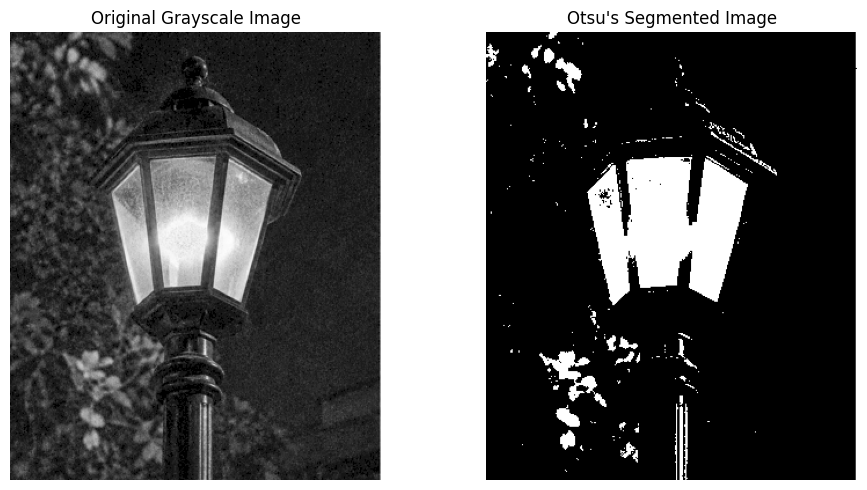

In [2]:

import cv2
import matplotlib.pyplot as plt

# Step 1: Read the input grayscale image
img = cv2.imread('/content/denoising.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()

# Step 2: Apply Otsu's Global Thresholding
threshold_value, segmented_image = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 3: Display threshold value
print("Optimal Threshold Value:", threshold_value)

# Step 4: Display original and segmented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title("Otsu's Segmented Image")
plt.axis('off')

plt.tight_layout()
plt.show()
